# The gross code, written from its two polynomials

IBM's gross code memory circuit is a Stim file of 26,411 lines. Read line by line it looks like something nobody could
write by hand. This notebook writes the same circuit from scratch, starting from two short polynomials,

$$A = x^3 + y + y^2, \qquad B = y^3 + x + x^2 \qquad \text{on a } 12 \times 6 \text{ torus,}$$

and shows that every part of it (the checks, the number of logical qubits, the gate order, the detectors) follows from them.
The code is in `bbcode.py` next to this notebook: numpy for the arithmetic, Stim to hold and simulate the circuit, nothing else.
The maths is written out in `polynomials_to_circuits.md`.

At the end, the circuit is decoded and its error rate compared with IBM's published number.

Run time: about 4 minutes, almost all of it in the decoding at the end.

In [ ]:
%pip install -q numpy stim matplotlib
# Optional, used once as an outside cross-check and for decoding at the end:
%pip install -q stabilizer-qec

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import stim

import bbcode as bb          # bbcode.py, next to this notebook

## 1. Cells on a torus, and what $x$ and $y$ mean

The code lives on a grid of $12 \times 6 = 72$ cells whose edges wrap around: leaving on the right brings you back on the
left, leaving at the top brings you back at the bottom. Cell $(i, j)$ gets the number $6i + j$.

$x$ means "move one cell in the 12-direction", $y$ means "move one cell in the 6-direction". So $x^3$ moves every cell three
steps right, and $y^2$ two steps up. In code, a move is just a list: entry number $c$ says where cell $c$ goes.

x^3 sends cell 0 to 18   cell 70 to 16   (cell 70 is (11, 4); 11 + 3 wraps to 2)
y   sends cell 5 to 0     (cell 5 is (0, 5); 5 + 1 wraps to 0)


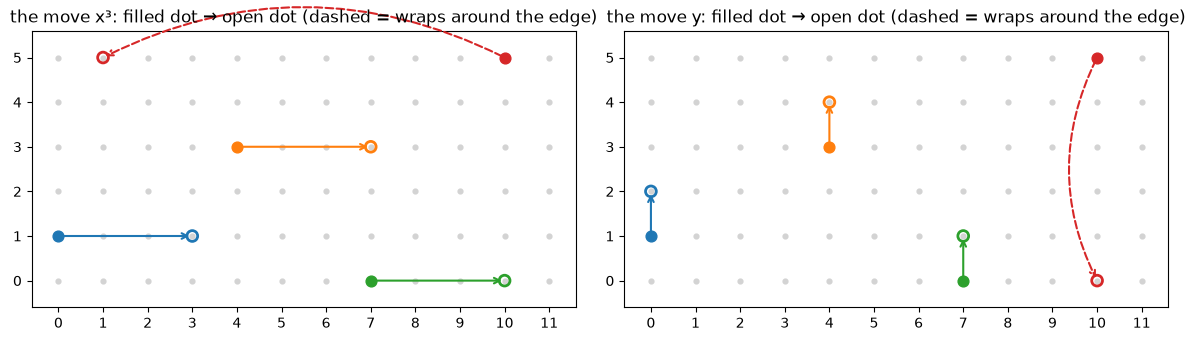

In [3]:
l, m = 12, 6
x3 = bb.shift(l, m, 3, 0)          # x^3
y1 = bb.shift(l, m, 0, 1)          # y
print("x^3 sends cell 0 to", x3[0], "  cell 70 to", x3[70], "  (cell 70 is (11, 4); 11 + 3 wraps to 2)")
print("y   sends cell 5 to", y1[5], "    (cell 5 is (0, 5); 5 + 1 wraps to 0)")

# draw where four sample cells go; every other cell moves the same way
fig, axs = plt.subplots(1, 2, figsize=(12, 3.2))
samples = [0 * m + 1, 4 * m + 3, 7 * m + 0, 10 * m + 5]
for ax, perm, label in [(axs[0], x3, "x³"), (axs[1], y1, "y")]:
    ax.scatter(*np.divmod(np.arange(l * m), m), s=12, color="lightgrey")
    for k, c in enumerate(samples):
        i, j = divmod(c, m); ti, tj = divmod(perm[c], m)
        colour = f"C{k}"
        ax.scatter([i], [j], s=60, color=colour); ax.scatter([ti], [tj], s=60, facecolors="none", edgecolors=colour, lw=2)
        wraps = abs(ti - i) > l / 2 or abs(tj - j) > m / 2
        ax.annotate("", xy=(ti, tj), xytext=(i, j), arrowprops=dict(arrowstyle="->", color=colour, lw=1.5,
                                                                    ls="--" if wraps else "-",
                                                                    connectionstyle="arc3,rad=0.25" if wraps else "arc3"))
    ax.set_title(f"the move {label}: filled dot → open dot (dashed = wraps around the edge)")
    ax.set_aspect("equal"); ax.set_xticks(range(l)); ax.set_yticks(range(m)); ax.set_xlim(-0.6, l - 0.4); ax.set_ylim(-0.6, m - 0.4)
plt.tight_layout(); plt.show()

Every cell moves the same way. That is the whole reason the gross code is regular: everything below is built from six
such moves.

## 2. A polynomial is a sum of moves, and that is a matrix

Write a move as a $72 \times 72$ matrix with one 1 per row: row $c$ has its 1 in column (where $c$ goes). Adding moves
(mod 2) gives a matrix with three 1s per row. That is what $A = x^3 + y + y^2$ means as a matrix.

There are 144 data qubits, two per cell: an **L** qubit and an **R** qubit. There are 72 X checks and 72 Z checks, one of
each per cell. The paper defines

$$H_X = [\,A \mid B\,], \qquad H_Z = [\,B^{\top} \mid A^{\top}\,].$$

Row $c$ of $H_X$ is the X check in cell $c$: the three 1s of $A$ are the L qubits it touches, the three 1s of $B$ the R qubits.

H_X: (72, 144)   H_Z: (72, 144)
qubits per check: {np.uint64(6)}    checks (of each type) per qubit: {np.uint64(3)}


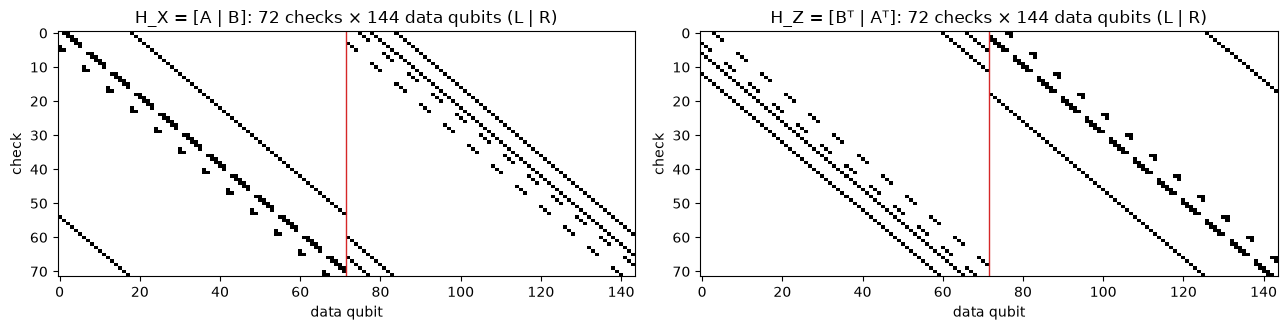

In [4]:
gross = bb.gross_code()
HX, HZ = gross.check_matrices()
print("H_X:", HX.shape, "  H_Z:", HZ.shape)
print("qubits per check:", set(HX.sum(axis=1)), "   checks (of each type) per qubit:", set(HX.sum(axis=0)))

fig, axs = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, H, t in [(axs[0], HX, "H_X = [A | B]"), (axs[1], HZ, "H_Z = [Bᵀ | Aᵀ]")]:
    ax.imshow(H, cmap="Greys", aspect="auto", interpolation="nearest")
    ax.axvline(71.5, color="tab:red", lw=1)
    ax.set_title(f"{t}: 72 checks × 144 data qubits (L | R)"); ax.set_xlabel("data qubit"); ax.set_ylabel("check")
plt.tight_layout(); plt.show()

Each diagonal stripe is one term: a move is a shifted identity. Each check touches 6 qubits and each qubit sits in 3 X
and 3 Z checks. That small, fixed number is what "LDPC" (low-density parity check) means.

## 3. Do the checks fit together, and how many logical qubits are there?

**Commuting.** An X check and a Z check can be measured together only if they overlap on an even number of qubits. For all
pairs at once, that is $H_X H_Z^{\top} = 0 \pmod 2$. Here $H_X H_Z^{\top} = AB + BA$, and $AB = BA$ because moves on a
grid can be done in either order. So the condition holds for any two polynomials.

**Counting.** Each independent check removes one degree of freedom from the 144 qubits; what is left is logical qubits:

$$k = n - \operatorname{rank} H_X - \operatorname{rank} H_Z \pmod 2.$$

The rank is computed by Gaussian elimination where $1 + 1 = 0$ (`gf2_rank` in `bbcode.py`, about 20 lines).

In [5]:
print("checks commute:", gross.checks_commute())
print("rank H_X =", bb.gf2_rank(HX), "  rank H_Z =", bb.gf2_rank(HZ), "  ->  k =", gross.k)

# the same grid with the simplest polynomials, A = 1 + x, B = 1 + y, is the toric code
A = (np.eye(72, dtype=int)[bb.shift(l, m, 0, 0)] + np.eye(72, dtype=int)[bb.shift(l, m, 1, 0)]) % 2
B = (np.eye(72, dtype=int)[bb.shift(l, m, 0, 0)] + np.eye(72, dtype=int)[bb.shift(l, m, 0, 1)]) % 2
print("toric code on the same 12 x 6 torus: k =", 144 - bb.gf2_rank(np.hstack([A, B])) - bb.gf2_rank(np.hstack([B.T, A.T])))

checks commute: True
rank H_X = 66   rank H_Z = 66   ->  k = 12
toric code on the same 12 x 6 torus: k = 2


Only 66 of the 72 X checks are independent (and 66 of the 72 Z checks): $144 - 66 - 66 = 12$. The toric code on the same
grid keeps 71 of each and stores 2. The six extra dependencies are what the gross polynomials buy: ten times as many logical
qubits on the same 144 data qubits.

All 72 checks of each type are still measured. Dropping 6 would break the pattern that every cell looks the same, which is
what makes the circuit below so short to write.

## 4. Logical operators

A logical Z operator is a set of Z flips on data qubits that commutes with every X check ($H_X v = 0$) but is not itself a
product of Z checks. `logical_z()` takes all solutions of $H_X v = 0$ and keeps those that add something new beyond the rows
of $H_Z$, until it has 12. The same with X and Z exchanged gives the logical X operators.

logical Z weights: [12, 12, 12, 12, 12, 12, 24, 12, 36, 34, 28, 38]
logical X weights: [12, 12, 12, 12, 12, 12, 12, 12, 14, 12, 14, 14]
each logical X anticommutes with exactly the right logical Zs: rank of LX·LZᵀ = 12


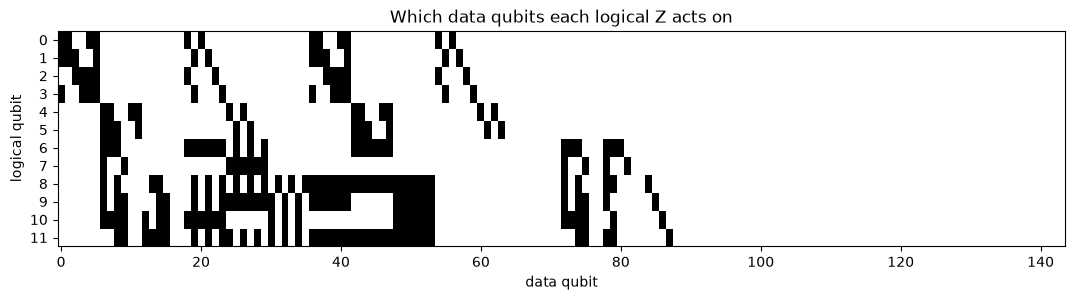

In [6]:
LZ, LX = gross.logical_z(), gross.logical_x()
print("logical Z weights:", LZ.sum(axis=1).tolist())
print("logical X weights:", LX.sum(axis=1).tolist())
print("each logical X anticommutes with exactly the right logical Zs: rank of LX·LZᵀ =", bb.gf2_rank(LX.astype(int) @ LZ.T % 2))

fig, ax = plt.subplots(figsize=(13, 2.8))
ax.imshow(LZ, cmap="Greys", aspect="auto", interpolation="nearest")
ax.set_xlabel("data qubit"); ax.set_ylabel("logical qubit"); ax.set_yticks(range(12))
ax.set_title("Which data qubits each logical Z acts on"); plt.show()

None is lighter than 12, the code distance (proving that no lighter one exists is a separate, harder computation).
Many data qubits are used by several logical operators. That overlap is why a gate cannot act on one logical qubit alone.

## 5. The Tanner graph, drawn on the torus

Put the four kinds of qubit of each cell next to each other (L, R, X check, Z check) and draw a line wherever a check
touches a data qubit. That picture is the code's Tanner graph.

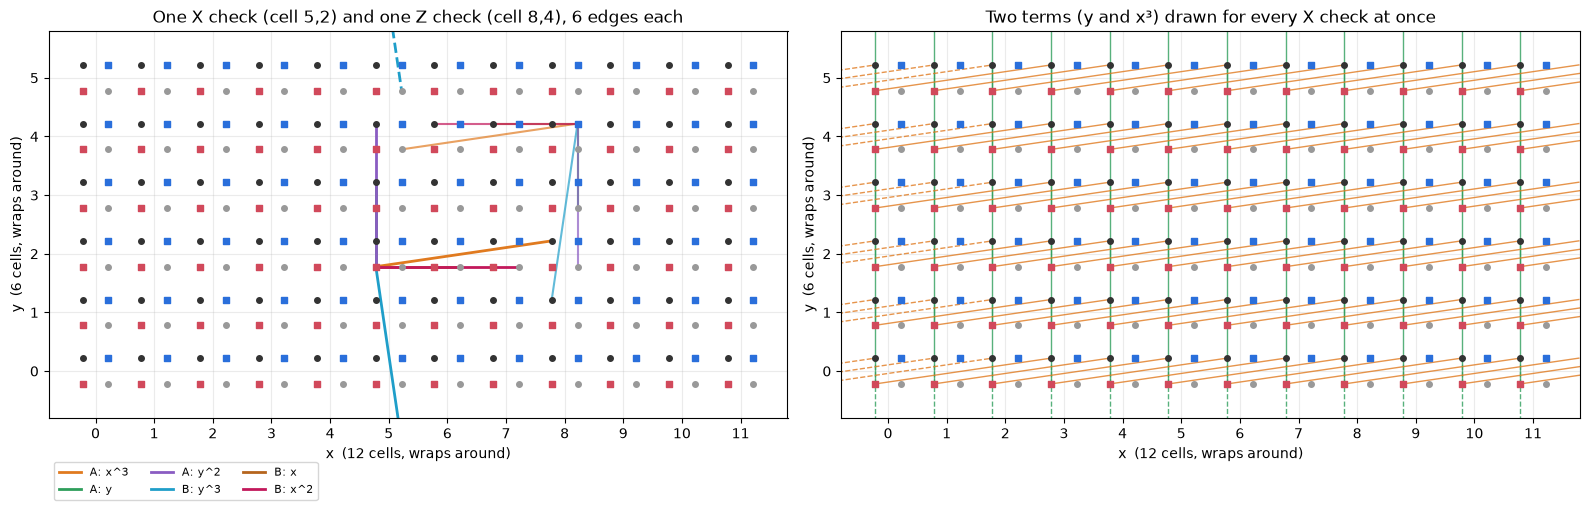

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5.5))
cols = gross.draw_tanner(axs[0], x_checks=[5 * m + 2], z_checks=[8 * m + 4])
names = [bb.term_name(a, b) for a, b in gross.A_terms + gross.B_terms]
for t, name in enumerate(names):
    axs[0].plot([], [], color=cols[t], lw=2, label=("A: " if t < 3 else "B: ") + name)
axs[0].legend(fontsize=8, ncol=3, loc="upper left", bbox_to_anchor=(0, -0.1))
axs[0].set_title("One X check (cell 5,2) and one Z check (cell 8,4), 6 edges each")
gross.draw_tanner(axs[1], all_x_terms=[("L", 1), ("L", 0)])
axs[1].set_title("Two terms (y and x³) drawn for every X check at once")
plt.tight_layout(); plt.show()

Left: two of each check's six edges go to a neighbouring cell (the terms $y$ and $x$, like a toric code); the other four
reach two or three cells away. Those are the long-range connections a surface code does not have.

Right: one term is the same move from every cell. So "every X check does its CNOT through term $y$" is a single layer of
72 CNOTs in which no qubit appears twice. **One term = one time step of the circuit.** That is what makes the circuit short
to write.

## 6. From a check to gates

Measuring a check with a helper (ancilla) qubit:

| | X check | Z check |
|---|---|---|
| prepare the check qubit | `RX` (state $|+\rangle$) | `R` (state $|0\rangle$) |
| one CNOT per data qubit it touches | check qubit controls, data qubit is target | data qubit controls, check qubit is target |
| read it out | `MX` | `M` |

With six terms per check, that is six CNOT layers per check type. The order of those layers is the **schedule**. Two schedules
are written in `bbcode.py`:

- **simple**: all six X layers, measure X; then all six Z layers, measure Z. Always correct for any code of this kind,
  because X and Z gates never mix. Each qubit spends a lot of time waiting.
- **depth-8** (Bravyi et al.): X and Z checks work at the same time on different halves of the data, so a round takes 8 time
  steps. Step by step:

In [8]:
rows = []
for step in range(7):
    xs, zs = gross.DEPTH8_X[step], gross.DEPTH8_Z[step]
    term = lambda s: "" if s is None else f"{'A' if (s[0] == 'L') == True else 'B'}{s[1] + 1} on {s[0]}"
    xdesc = "prepare (RX)" if xs is None else f"CX via {bb.term_name(*(gross.A_terms if xs[0] == 'L' else gross.B_terms)[xs[1]])} → {xs[0]} data"
    zdesc = "measure (M)" if zs is None else f"CX via {bb.term_name(*(gross.B_terms if zs[0] == 'L' else gross.A_terms)[zs[1]])} ← {zs[0]} data"
    rows.append((step + 1, xdesc, zdesc))
rows.append((8, "measure (MX)", "reset (R) for the next round"))
import pandas as pd
pd.DataFrame(rows, columns=["step", "X checks", "Z checks"]).set_index("step")

,X checks,Z checks
step,,
1,prepare (RX),CX via x^3 ← R data
2,CX via y → L data,CX via y^2 ← R data
3,CX via x → R data,CX via y^3 ← L data
4,CX via y^3 → R data,CX via x ← L data
5,CX via x^2 → R data,CX via x^2 ← L data
6,CX via x^3 → L data,CX via y ← R data
7,CX via y^2 → L data,measure (M)
8,measure (MX),reset (R) for the next round


Steps 2–6 each run 144 CNOTs: 72 for the X checks and 72 for the Z checks, on different qubits. This order is not
obvious: Bravyi et al. found it by a computer search. We took it from the paper's circuit (as generated by `stabilizer-qec`) and wrote it as the two seven-entry lists above.

**Why the order matters.** When an X check and a Z check share data qubits and their CNOTs are interleaved, the circuit
still measures the right thing only if, among the shared qubits, the number where the X check's CNOT comes first is
**even**. (Each such qubit swaps two actions that anticommute; an odd number leaves a sign that makes the result random.)
`schedule_conflicts` counts the X/Z pairs that break this rule:

In [9]:
print("depth-8 order: pairs breaking the rule =", gross.schedule_conflicts())
z_swapped = list(gross.DEPTH8_Z); z_swapped[1], z_swapped[4] = z_swapped[4], z_swapped[1]
print("same order with Z steps 2 and 5 swapped:", gross.schedule_conflicts(gross.DEPTH8_X, z_swapped))

depth-8 order: pairs breaking the rule = 0
same order with Z steps 2 and 5 swapped: 216


Swapping just two of the Z steps breaks the rule for 216 pairs; a circuit built that way has detectors that fire even with
no noise. The simple schedule never has this problem, because all X CNOTs come before all Z CNOTs.

The time-step picture of one round for both schedules:

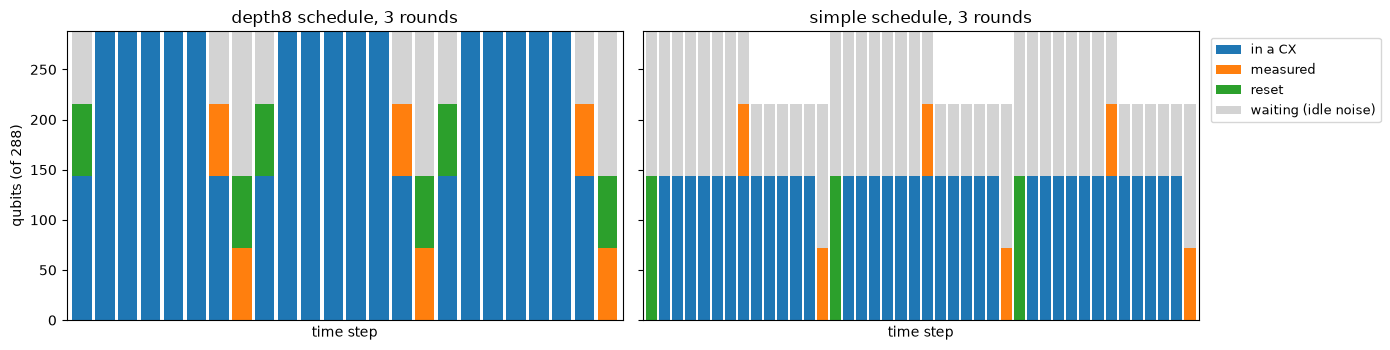

In [10]:
def qubits_per_step(c):
    # for each time step: how many qubits are in a CX, being measured, being reset, or waiting
    steps, cur = [], {"in a CX": 0, "measured": 0, "reset": 0, "waiting (idle noise)": 0}
    for inst in c.flattened():
        n = len(inst.targets_copy())
        if inst.name == "TICK":
            steps.append(cur); cur = dict.fromkeys(cur, 0)
        elif inst.name == "CX": cur["in a CX"] += n
        elif inst.name in ("M", "MX"): cur["measured"] += n
        elif inst.name in ("R", "RX"): cur["reset"] += n
        elif inst.name == "DEPOLARIZE1": cur["waiting (idle noise)"] += n
    return pd.DataFrame(steps)

fig, axs = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
for ax, sched in zip(axs, ["depth8", "simple"]):
    t = qubits_per_step(gross.memory_circuit(3, 0.001, sched)).iloc[1:]   # skip the initial reset step
    t.plot.bar(stacked=True, ax=ax, width=0.85, color=["tab:blue", "tab:orange", "tab:green", "lightgrey"], legend=False)
    ax.set_title(f"{sched} schedule, 3 rounds"); ax.set_xlabel("time step"); ax.set_xticks([])
axs[0].set_ylabel("qubits (of 288)")
axs[1].legend(*axs[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.tight_layout(); plt.show()

In the depth-8 rounds all 288 qubits are in a CNOT in steps 2–6, and the waiting (grey) is confined to the steps around
the measurements. The simple rounds take 14 steps, and in every CNOT layer only 144 of the 288 qubits are busy; most of the rest wait. (The blank
part of the simple bars is the X check qubits after they have been measured: they do nothing until their next reset.) Waiting costs noise, which shows up in the error rate in section 9.

## 7. Writing the circuit

`memory_circuit(rounds, p, schedule)` puts it together:

1. reset the 144 data qubits to $|0\rangle$ (a Z-basis memory),
2. one round; each Z check is a **detector** on its own (it must read 0 on $|0\ldots0\rangle$),
3. the other rounds in a Stim `REPEAT` block; each check is compared with itself one round earlier,
4. measure all data qubits; rebuild each Z check from them and compare with its last measured value,
5. one **observable** per logical Z operator, read from the final data measurement.

Noise is "uniform circuit noise", as in IBM's files: after every reset, gate and measurement, and on every waiting qubit in
every time step, an error with probability $p$.

In [11]:
P = 0.004
circuit = gross.memory_circuit(12, P, "depth8")
text = str(circuit)
print(f"{len(text.splitlines())} lines (IBM's file for the same experiment: 26,411)\n")
print("\n".join(line[:110] for line in text.splitlines()[288:300]))

586 lines (IBM's file for the same experiment: 26,411)

R 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 3
X_ERROR(0.004) 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 
R 216 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233 234 235 236 237 238 239 240 241 242 
X_ERROR(0.004) 216 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233 234 235 236 237 238 239
TICK
RX 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161 162 163 164 165 166 167 168 169 170
Z_ERROR(0.004) 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161 162 163 164 165 166 167
CX 72 234 73 235 74 236 75 237 76 238 77 239 78 240 79 241 80 242 81 243 82 244 83 245 84 246 85 247 86 248 87
DEPOLARIZE2(0.004) 72 234 73 235 74 236 75 237 76 238 77 239 78 240 79 241 80 242 81 243 82 244 83 245 84 246 
DEPOLARIZE1(0.004) 0 1 2 3 4 5 6 7 8 9 10 11 12 13 

The first 288 lines are coordinates (where each qubit sits, used only for drawing). The circuit proper starts after them:
resets, then CNOT layers written as one line each. Most of the difference from IBM's 26,411 lines is that IBM writes one gate
per line and every round out in full; the content is the same.

## 8. Sanity checks

1. **Silent without noise.** With $p = 0$ no detector may ever fire and no observable may ever flip. If a detector or an
   observable were wrong, this is where it would show.
2. **Same size as IBM's circuit.**
3. **Same matrices as an independent implementation** (`stabilizer-qec`), if installed.

In [12]:
quiet = gross.memory_circuit(12, 0.0, "depth8")
dets, obs = quiet.compile_detector_sampler().sample(500, separate_observables=True)
print("1. noiseless, 500 shots: any detector fired?", dets.any(), "  any observable flipped?", obs.any())

full = gross.memory_circuit(12, P, "depth8", z_detectors_only=False)
cx = sum(len(i.targets_copy()) // 2 for i in full.flattened() if i.name == "CX")
print(f"2. qubits {full.num_qubits} (IBM 288), CX {cx} (IBM 10,368), detectors {full.num_detectors} "
      f"(IBM 1,728), Z detectors only {circuit.num_detectors} (IBM after its filter: 936)")
try:
    import stabilizer_qec as sq
    sHX, sHZ = sq.BivariateBicycleCode("gross").check_matrices()
    print("3. same H_X and H_Z as stabilizer-qec:", np.array_equal(HX, np.asarray(sHX)) and np.array_equal(HZ, np.asarray(sHZ)))
except ImportError:
    print("3. stabilizer-qec not installed: skipped")

1. noiseless, 500 shots: any detector fired? False   any observable flipped? False


2. qubits 288 (IBM 288), CX 10368 (IBM 10,368), detectors 1728 (IBM 1,728), Z detectors only 936 (IBM after its filter: 936)
3. same H_X and H_Z as stabilizer-qec: True


`test_bbcode.py` runs these checks and more (`python -m pytest -q test_bbcode.py`, about 5 seconds). It also confirms that,
after matching up the qubit numbering, our depth-8 circuit has the same gates in the same time steps and the same detectors
and observables as the circuit `stabilizer-qec` generates.

## 9. Decoding it

Stim turns the noisy circuit into a **detector error model**: every possible fault, its probability, which detectors it
lights and which logical observables it flips. The decoder gets that and the detector results of each shot.

One trap, found while writing this: with a `REPEAT` block in the circuit, Stim (1.16) lists 2,376 faults twice instead of
merging them, and BP-based decoders then do worse (7.3% instead of 3.1% failures at $p = 0.004$ on the same shots). So the
error model is built from the flattened circuit: `gross.detector_error_model(...)`.

In [13]:
print("faults, from the circuit as written:", circuit.detector_error_model(decompose_errors=False).num_errors)
print("faults, from the flattened circuit:  ", gross.detector_error_model(12, P).num_errors)

faults, from the circuit as written: 11160


faults, from the flattened circuit:   8784


Decoding with BP-OSD (IBM's settings: min-sum, 80 iterations, OSD-CS order 10; from `stabilizer-qec`), 1,000 shots per
schedule. A shot fails if any of the 12 logical qubits comes out wrong.

In [14]:
import time
SHOTS = 1000
results = {}
try:
    import stabilizer_qec as sq
    for sched in ["depth8", "simple"]:
        c = gross.memory_circuit(12, P, sched)
        d, o = c.compile_detector_sampler(seed=7).sample(SHOTS, separate_observables=True)
        t = time.time()
        decoder = sq.BpOsd(gross.detector_error_model(12, P, sched), max_iter=80, bp_method="minimum_sum",
                           osd_method="osd_cs", osd_order=10)
        fails = int((np.asarray(decoder.decode_batch(d), bool) != o).any(axis=1).sum())
        results[sched] = fails
        print(f"{sched:7s}: {fails}/{SHOTS} failed ({fails / SHOTS:.1%})  in {time.time() - t:.0f} s")
except ImportError:
    print("stabilizer-qec not installed: decoding skipped")

depth8 : 29/1000 failed (2.9%)  in 27 s


simple : 718/1000 failed (71.8%)  in 69 s


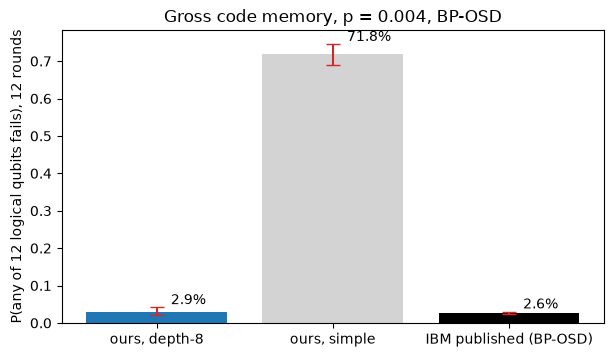

In [15]:
if results:
    from math import sqrt
    def wilson(f, n, z=1.96):
        p = f / n; den = 1 + z * z / n; mid = (p + z * z / (2 * n)) / den
        half = z * sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
        return mid - half, mid + half
    labels = ["ours, depth-8", "ours, simple", "IBM published (BP-OSD)"]
    vals = [(results["depth8"], SHOTS), (results["simple"], SHOTS), (265, 10_000)]
    P_L = np.array([f / n for f, n in vals]); ci = np.array([wilson(f, n) for f, n in vals])
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.bar(labels, P_L, color=["tab:blue", "lightgrey", "black"])
    ax.errorbar(range(3), P_L, yerr=[P_L - ci[:, 0], ci[:, 1] - P_L], fmt="none", color="tab:red", capsize=5)
    for i, v in enumerate(P_L): ax.text(i + 0.08, ci[i, 1], f"{v:.1%}", va="bottom", ha="left")
    ax.set_ylabel("P(any of 12 logical qubits fails), 12 rounds"); ax.set_title(f"Gross code memory, p = {P}, BP-OSD")
    plt.show()

The depth-8 circuit written from the polynomials matches IBM's published error rate within the error bars. The simple
schedule, with the same code, the same checks and the same decoder, fails in most shots: with every qubit waiting through
about half of each round, the noise per round roughly doubles, which at this $p$ puts it above its threshold. The only
difference is the order of the gates. **The code fixes what is measured; the schedule decides how well it works.**

## Summary

| Step | How much code | Where |
|---|---|---|
| moves on the torus | 2 lines | `shift`, `inverse` |
| $H_X$, $H_Z$ from the polynomials | 6 lines | `check_matrices` |
| $k$ and logical operators | ~40 lines of mod-2 linear algebra | `gf2_*`, `logical_z/x` |
| one CNOT layer per polynomial term | 1 line per layer | `_x_pairs`, `_z_pairs` |
| the schedule | two 7-entry lists | `DEPTH8_X`, `DEPTH8_Z` |
| the whole memory circuit | ~40 lines | `memory_circuit` |

The same file builds the [[72,12,6]] code with `bb.bb72_code()` (a 6 × 6 torus, same polynomials); any other BB code is one
`BBCode(l, m, A, B)` call away.

## References

- S. Bravyi et al., *High-threshold and low-overhead fault-tolerant quantum memory*, Nature 627, 778 (2024), arXiv:2308.07915.
- C. Gidney, *Stim: a fast stabilizer circuit simulator*, Quantum 5, 497 (2021).
- J. Roffe et al., *Decoding across the quantum LDPC code landscape*, Phys. Rev. Research 2, 043423 (2020), arXiv:2005.07016.
- IBM's gross code circuits and published results: github.com/trmue/relay (Apache-2.0).